# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import ChaBuDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/chabud/",
    "mode": "train"
}
dataset = ChaBuDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 278


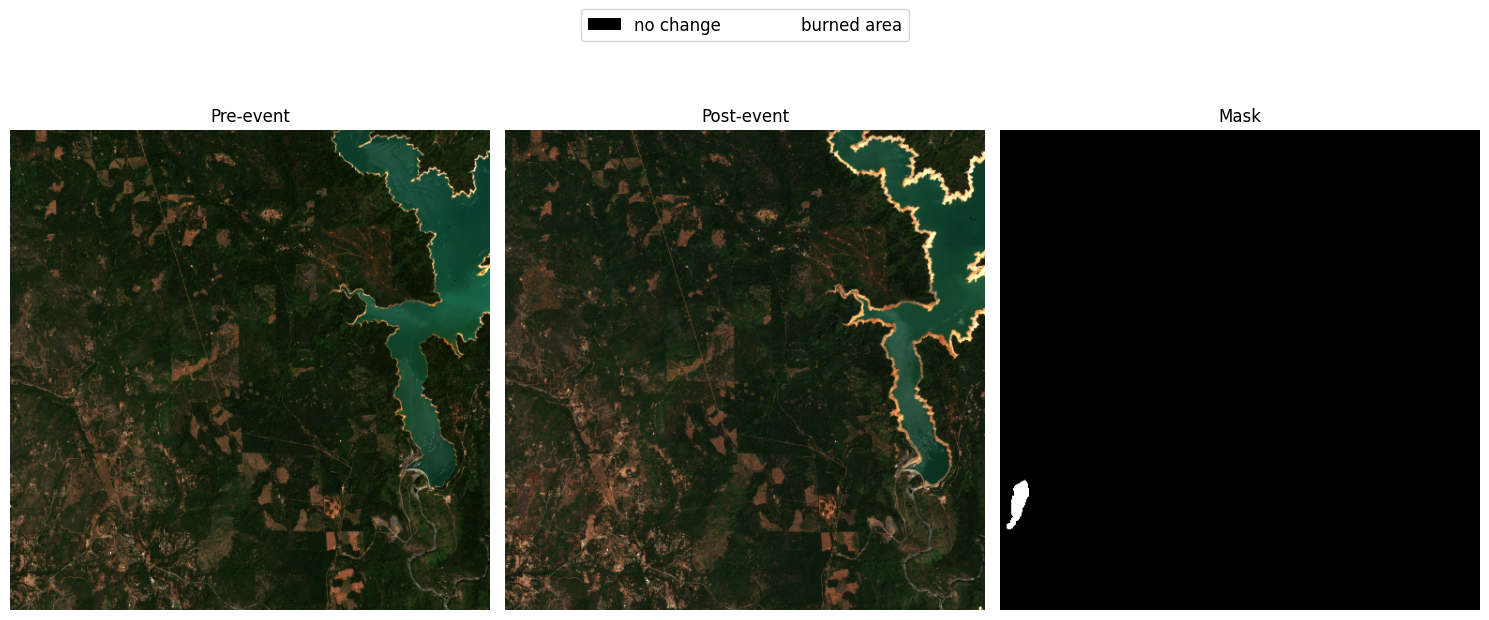

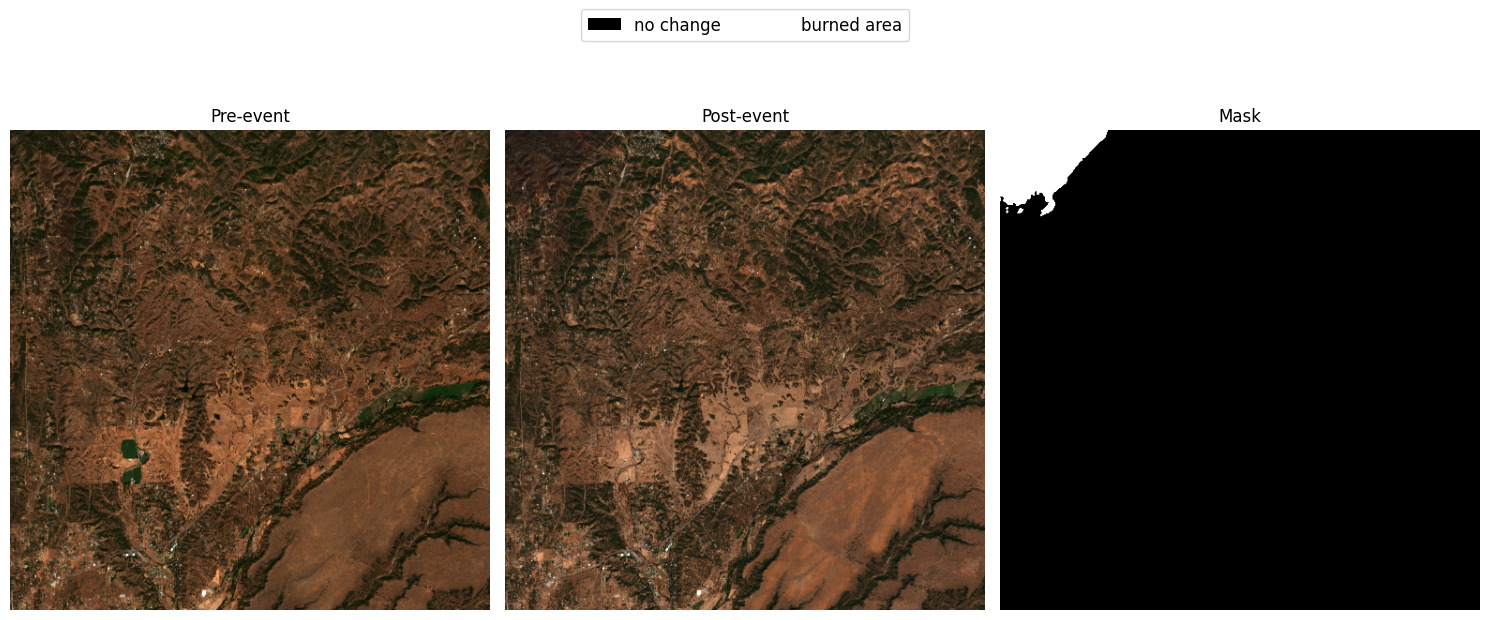

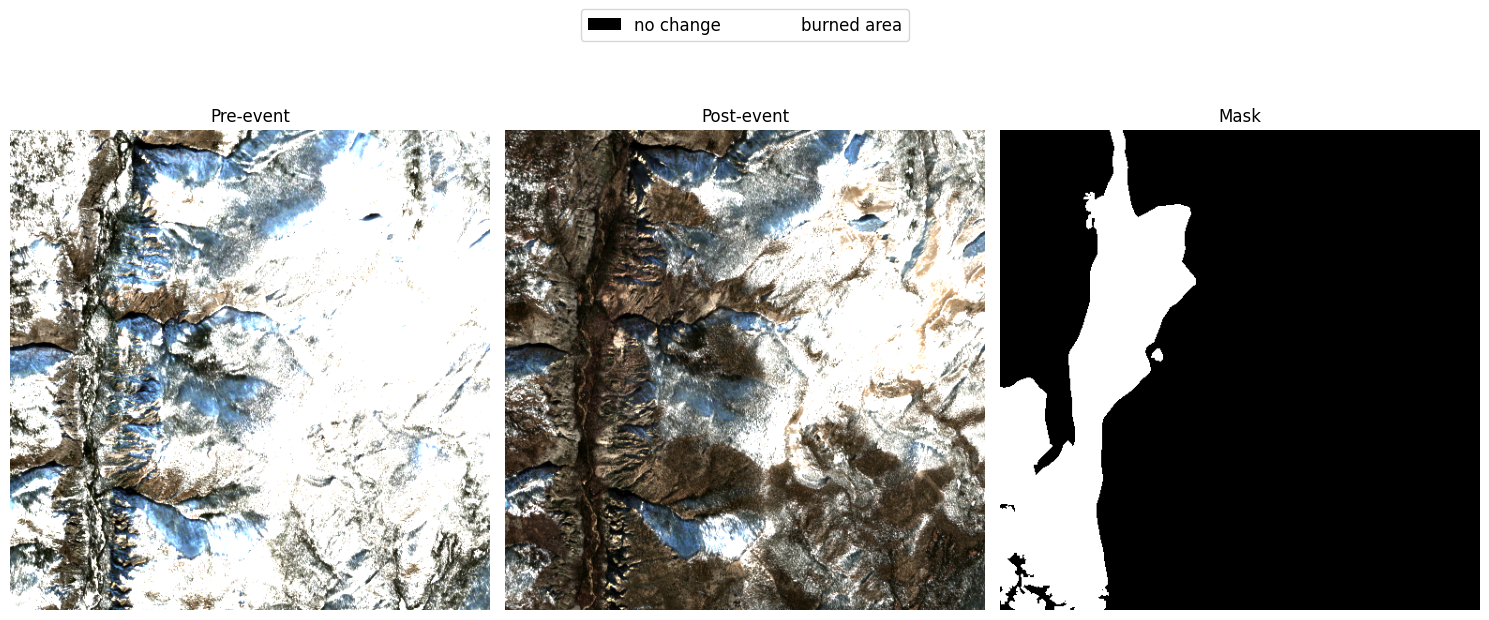

In [6]:
dataset.show_image(100);
dataset.show_image(150);
dataset.show_image(220);

In [36]:
dataset.data_distribution_table()

,Number of pixels
no change,68200932.0
burned area,4675100.0


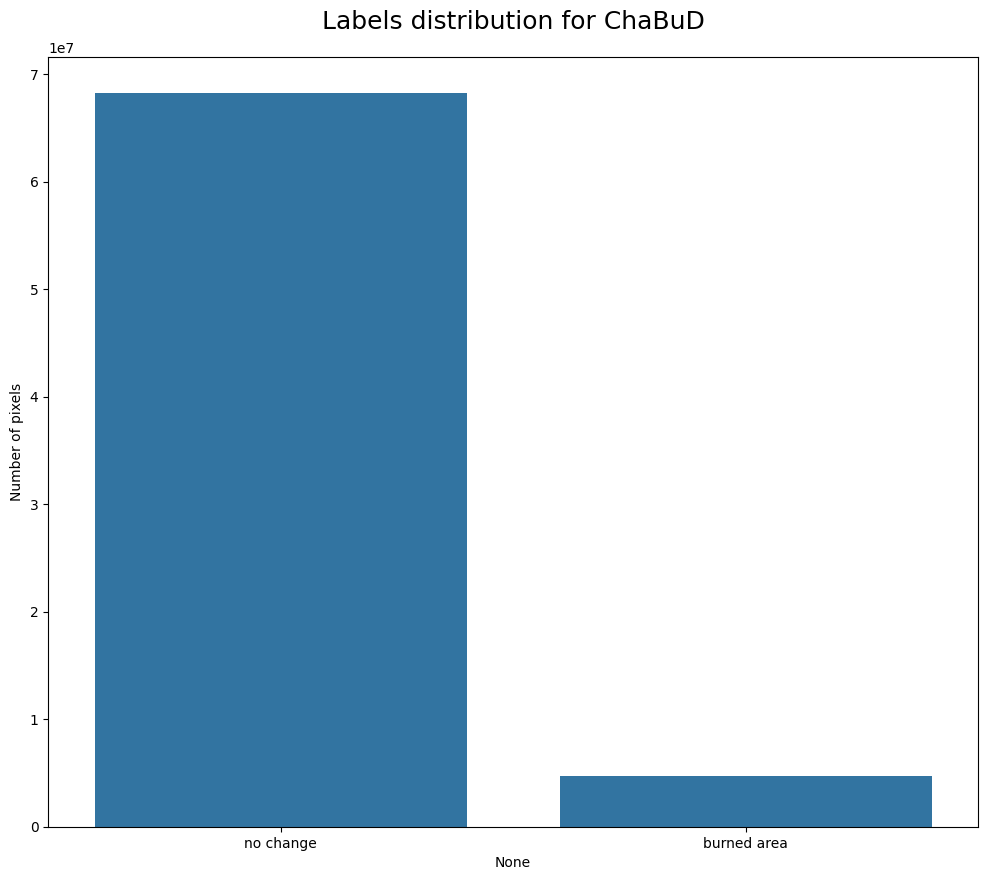

In [37]:
dataset.data_distribution_barchart();

## Load train and test data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/chabud/",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = ChaBuDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/chabud/",
    "mode": "validation",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = ChaBuDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(278, 78)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/chabud"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 07:54:40,856 INFO Starting training.
training: 100%|██████████| 35/35 [00:03<00:00,  9.28it/s]
2026-01-28 07:54:44,668 INFO epoch: 1, loss:  0.30384
testing on train set: 100%|██████████| 35/35 [00:02<00:00, 13.46it/s]
2026-01-28 07:54:48,484 INFO Accuracy:0.5951909401433931, Accuracy per Class:[0.82991923 0.36046266], Precision Micro:0.5588316862324978, Precision Macro:0.5071960215525528, Precision Weighted:0.8807133822863241, Precision per Class:[0.93328157 0.08111047], Recall Micro:0.8826449477765593, Recall Macro:0.8966105258618567, Recall Weighted:0.8826449477765594, Recall per Class:[0.88067946 0.9125416 ], F1_score Micro:0.6843676170299547, F1_score Macro:0.5275984474124339, F1_score Weighted:0.8595057616598697, F1_score per Class:[0.90621782 0.14897907], IOU:0.520181492861245, IOU mean:0.4545012231402052, IOU per Class:[0.82851763 0.08048481]
training: 100%|██████████| 35/35 [00:03<00:00, 10.39it/s]
2026-01-28 07:54:51,860 INFO epoch: 2, loss:  0.26094
testing on tra